# Mandatory assignment 3

**GitHub repository:** https://github.com/VinjarSvae-Grotli/TECH2-H26-assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

### 1.

In [130]:
import pandas as pd

file = 'SCF_10pct.csv'

data = pd.read_csv(file)

df = pd.DataFrame(data)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


### 2.

In [131]:
columns = ['id', 'year', 'age', 'educ', 'stocks', 'equity']

print(df[columns].isna().sum())

num_before = len(df)
df = df.dropna(subset=columns)
num_after = len(df)
print(f'Dropped {num_before - num_after} observations, {num_after} remain')

id         0
year       0
age        0
educ      16
stocks    18
equity    16
dtype: int64
Dropped 50 observations, 5758 remain


### 3.

In [132]:
num_before = len(df)
df = df[(df['age'] >= 25) & (df['age'] <= 89)]
num_after = len(df)
print(f'Dropped {num_before - num_after} observations, {num_after} remain')

Dropped 326 observations, 5432 remain


### 4.

In [133]:
df['direct'] = (df['stocks'] > 0).astype(int)
df['overall'] = (df['equity'] > 0).astype(int)
df.head(20)

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
6,6,1989,44,2.0,0.0,0.0,0,0
7,7,1989,55,1.0,0.0,0.0,0,0
8,8,1989,62,1.0,0.0,0.0,0,0
9,9,1989,77,1.0,6916.8,6916.8,1,1
10,10,1989,34,3.0,0.0,0.0,0,0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

### 1. and 2.

In [134]:
def participation_rate(indicator):
    count = 0
    n = 0

    for value in indicator:
        count += value
        n += 1
    return count / n * 100

print(f'Direct participation rate: {participation_rate(df['direct']):.2f}%')
print(f'Overall participation rate: {participation_rate(df['overall']):.2f}%')

Direct participation rate: 16.96%
Overall participation rate: 49.41%


### 3.

In [135]:
print(f'Direct participation rate: {df['direct'].mean()*100:.2f}%')
print(f'Overall participation rate: {df['overall'].mean()*100:.2f}%')

Direct participation rate: 16.96%
Overall participation rate: 49.41%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

### 1.

In [136]:
lst_direct = []
lst_overall = []

categories = range(1, 5)

for category in categories:
    df_educ = df[df['educ'] == category]
    direct = participation_rate(df_educ['direct'])
    lst_direct.append(direct)
    overall = participation_rate(df_educ['overall'])
    lst_overall.append(overall)

### 2.

In [137]:
results = pd.DataFrame({
    'Direct': lst_direct,
    'Overall': lst_overall
    }, index=categories)

results.round(1)

,Direct,Overall
1,4.4,17.3
2,11.4,39.9
3,13.5,48.3
4,30.5,73.5


### 3.

Text(0.5, 0.98, 'Stock market participation by education')

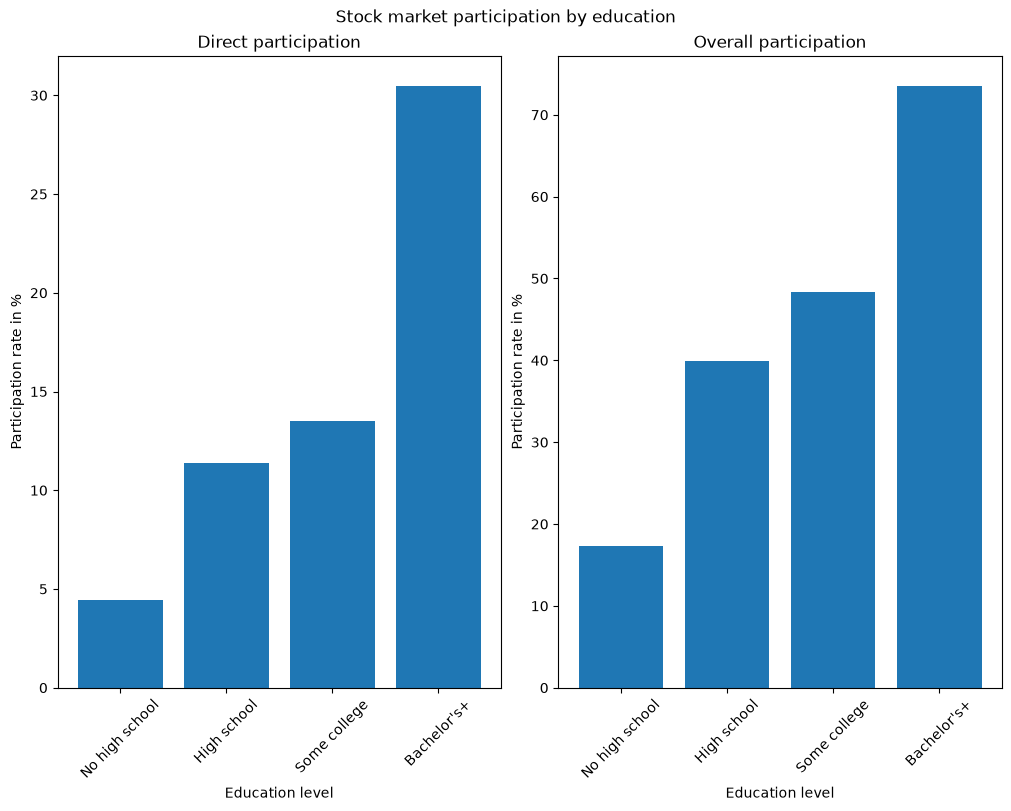

In [138]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, layout='constrained', figsize=(10, 8))

xvalues = categories
labels = ['No high school', 'High school', 'Some college', "Bachelor's+"]

yvalues1 = results['Direct']
yvalues2 = results['Overall']

axes[0].bar(xvalues, yvalues1)
axes[0].set_xticks(categories, labels, rotation=45)
axes[0].set_xlabel('Education level')
axes[0].set_ylabel('Participation rate in %')
axes[0].set_title('Direct participation')

axes[1].bar(xvalues, yvalues2)
axes[1].set_xticks(categories, labels, rotation=45)
axes[1].set_xlabel('Education level')
axes[1].set_ylabel('Participation rate in %')
axes[1].set_title('Overall participation')

fig.suptitle('Stock market participation by education')

### 4.

The data shows that higher education correlates with having a higher direct and overall participation rate. The direct participation rate more than doubles between Some College and Bachelor's+. Overall participation rates have smaller relative differences, but there are major differences when evaluated in terms of percentage points.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

### 1.

In [139]:
lst_direct = []
lst_overall = []

years = sorted(df['year'].unique())

for year in years:
    df_year = df[df['year'] == year]
    direct = participation_rate(df_year['direct'])
    lst_direct.append(direct)
    overall = participation_rate(df_year['overall'])
    lst_overall.append(overall)

results = pd.DataFrame({
    'Direct': lst_direct,
    'Overall': lst_overall
    }, index=years)

results.round(1)


,Direct,Overall
1989,15.6,31.6
1992,18.3,40.1
1995,15.7,45.9
1998,19.9,51.2
2001,21.8,57.0
2004,18.9,54.7
2007,17.3,56.5
2010,17.4,50.3
2013,14.8,49.9
2016,12.3,52.0


### 2.

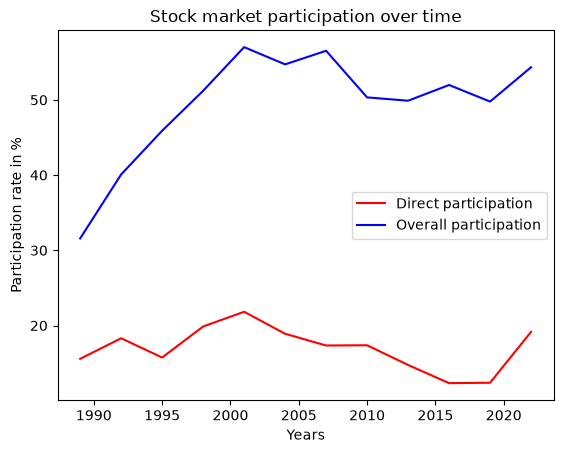

In [140]:
xvalues = years

yvalues1 = results['Direct']
yvalues2 = results['Overall']

plt.plot(xvalues, yvalues1, color='red')
plt.plot(xvalues, yvalues2, color='blue')


plt.title('Stock market participation over time')
plt.xlabel('Years')
plt.ylabel('Participation rate in %')
plt.legend(['Direct participation', 'Overall participation']);

### 3.

In [141]:
change = results.loc[2022] - results.loc[1989]

print(f'Direct: {change['Direct']:.1f} percentage points')
print(f'Overall: {change['Overall']:.1f} percentage points')

Direct: 3.6 percentage points
Overall: 22.8 percentage points


### 4.

Since the survey's start in 1989, to the latest survey in 2022, direct participation has seen increase of 3.6 percentage points, and overall participation has seen an increase of 22.8 percentage points. Overall participation saw a steady increase until its peak around 2001 before it levelled off. Direct also reached its peak at the same time, but then saw a decrease until 2019, where the trend is rising again in the latest survey.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I have used AI (Claude) when I got stuck on certain problems, which mostly happened in part 1.2, 3.1 and 3.2. In Part 3.4, it checked my description against the data and pointed out that I should specify whether I meant relative differences or percentage points. Similarly in 4.4 it helped me clear up my wording, nevertheless the analysis and draft was my own.

My AI does not give me solutions or code that I paste in without looking at. Rather it gives me pointers to what I'm doing wrong, and tells me where in my earlier code from the lectures and workshops I can take inspiration from. In the cases where I do not get it, it gives me part of the code, and I do my best to have it explain so I can understand. Then I write the code in a way that makes sense to me, often making the variables differently or expanding the code so it is more clear.

For future work I think I should rely less on AI to get better at problem solving and be prepared for the exam. As of now, AI is a great tool for me to learn and explore options.